In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import scipy.special as sci #for bessel funcion

In [5]:
#import csv file for ROI pixel list
def import_roi (roi_file):
    roi = np.genfromtxt(roi_file, delimiter=',')
    roi_intensities = roi[1:len(roi),3] #deixa somente as intensidades
    return (roi_intensities)

#normalize intensities using Frobenius norm
def normalize_roi (roi_intensities):
    roi_normalized = roi_intensities/np.linalg.norm (roi_intensities)
    return (roi_normalized, np.linalg.norm (roi_intensities))

#Gaussian parameters
def gauss_param(dataset):
    v = np.mean(dataset)
    s = np.std(dataset)
    return (v,s)

#Gaussian pdf
def func_gauss(x, v, s):
    g = (1/np.sqrt(2*np.pi*np.square(s)))*np.exp(-(np.square(x-v))/(2*np.square(s)))
    return g

#Rice pdf
def func_rice(x, v, s):
    r = (x/s**2)*np.exp(-1*(x**2+v**2)/(2*s**2))*sci.iv(0,x*v/(s**2))
    return r

#standard error of estimate (s)
def s_measure(observed_score, predicted_score, n_scores):
    s = np.sqrt(np.sum(np.square(observed_score-predicted_score))/(n_scores-2))
    return s

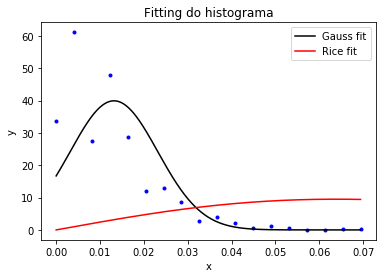

In [14]:
#--script for concatenated histograms--
#initialize concatenated histogram
concat_data = []
concat_data = np.array(concat_data)

#import ROIs and append
for i in range(2,3):
    data = import_roi('ar1_3T (%d).csv' % i)    
    concat_data = np.append(concat_data,data)

#normalize intensities
concat_data, norm = normalize_roi(concat_data)

#make histogram from intensities
[data_hist, data_bins] = np.histogram(concat_data, bins='doane', density=True)

#separate into xdata (bins with intensities) and ydata (count)
xdata = data_bins[0:len(data_bins)-1] 
ydata = data_hist
#plot intensity distribution data
plt.plot(xdata, ydata, 'b.')

#--fit curves to data--

#Gauss parameters
gauss_v, gauss_s = gauss_param(concat_data) #uses original data

#Rice optimal parameters
rice_param, pcov = curve_fit(func_rice, xdata, ydata) #uses np.histogram data

#obtain Gauss and Rice fitted curves
x_expec = np.linspace(0, xdata.max(), 1000)
y_gauss = func_gauss(x_expec, gauss_v, gauss_s)
y_rice = func_rice(x_expec, rice_param[0], rice_param[1])

#--end of fitting--
'''
#--calculation of standard error of estimate (SEE)--
#obtain Gauss and Rice ydata corresponding to original xdata
y_gauss_SEE = func_gauss(xdata, gauss_v, gauss_s)
y_rice_SEE = func_rice(xdata, rice_param[0], rice_param[1])
#calculate SEE
print xdata
gauss_SEE = s_measure(y_gauss_SEE, concat_data, concat_data.size)
rice_SEE = s_measure(y_rice_SEE, ydata, ydata.size)
print gauss_SEE
print rice_SEE'''


#plot
plt.plot(x_expec, y_gauss, 'k', label='Gauss fit')
plt.plot(x_expec, y_rice, 'r', label='Rice fit')
plt.title("Fitting do histograma")
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()